# Exercise 1

## Performing a classification task with titanic dataset using RandomForest method without cross-validation.

a) Download the titanic dataset from the supplied URL: ``` https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv ```

b) This is a classification task with two classes in which the labels are stored in “Survived”.

c) As the classification method you will be using [RandomForest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)

d) You will be using all features supplied which are: Pclass (categorical), Name, Sex (Categorical), Age,  Siblings/Spouses Aboard, Parents/Children Aboard and Fare.

e) Initialize RandomForest with 10 trees.
``` from sklearn.ensemble import RandomForestClassifier ```

f) Train the classifier with training data which is 80% of the whole dataset. In this example we do not use validation data. There is also no cross validation.

g) Drop unnecessary columns. In this example we drop only “Name” even though many other column can be irrelevant.

h) Apply one-hot encoding for the categorical variables.

i) Drop examples with NA values. ``` dropna() ```

j) Train the classifier ad make predictions on test data.

k) Calculate the accuracy of the mode in test data.
``` from sklearn.metrics import accuracy_score ```

# Exercise 2

Re-perform the second exercise by applying [feature selection](https://scikit-learn.org/stable/modules/feature_selection.html).

Print out the name of top **three** (```n_features_to_select=3```) features selected. To do so you need to use ```get_support()```.

### Resolution exercise 1

- Starting by downloading the `titanic dataset` from the given `URL`

- Also import the dependencies

In [3]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn

ERROR:root:code for hash blake2b was not found.
Traceback (most recent call last):
  File "/Users/andreatoffali/.pyenv/versions/3.11.9/lib/python3.11/hashlib.py", line 307, in <module>
    globals()[__func_name] = __get_hash(__func_name)
                             ^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/andreatoffali/.pyenv/versions/3.11.9/lib/python3.11/hashlib.py", line 129, in __get_openssl_constructor
    return __get_builtin_constructor(name)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/andreatoffali/.pyenv/versions/3.11.9/lib/python3.11/hashlib.py", line 123, in __get_builtin_constructor
    raise ValueError('unsupported hash type ' + name)
ValueError: unsupported hash type blake2b
ERROR:root:code for hash blake2s was not found.
Traceback (most recent call last):
  File "/Users/andreatoffali/.pyenv/versions/3.11.9/lib/python3.11/hashlib.py", line 307, in <module>
    globals()[__func_name] = __get_hash(__func_name)
                             ^^^^^^^^^^^^^^^^^^^^^^

In [4]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.metrics import accuracy_score 
from sklearn.ensemble import RandomForestClassifier

Let's add a global configuration in order to complete the **Data Analysis**, in particular:

1. Configuration


In [5]:
# configuration 
RANDOM_STATE = 42
CSV_PATH = "titanic.csv"
TARGET_COL = "Survived"

2. Load Data

    - Creating the dataframe by loading the dataset of `titanic`

In [6]:
df = pd.read_csv(CSV_PATH)

In [7]:
print("DataFrame shape:", df.shape)

DataFrame shape: (887, 8)


In [8]:
df.head()

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


3. Exploratory Data Analysis (EDA)

    - Here we are going to understand about the data in a better way

In [9]:
df.columns

Index(['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'Siblings/Spouses Aboard',
       'Parents/Children Aboard', 'Fare'],
      dtype='str')

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Survived                 887 non-null    int64  
 1   Pclass                   887 non-null    int64  
 2   Name                     887 non-null    str    
 3   Sex                      887 non-null    str    
 4   Age                      887 non-null    float64
 5   Siblings/Spouses Aboard  887 non-null    int64  
 6   Parents/Children Aboard  887 non-null    int64  
 7   Fare                     887 non-null    float64
dtypes: float64(2), int64(4), str(2)
memory usage: 55.6 KB


Numerical columns, we can selecti by saying that take this dataframe, select all the columns where the data type is a number `np.number` and create a lsit

In [11]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()

# remove the target column
num_cols.remove(TARGET_COL)

# Pclass is a numeric columns but categorical for the meaning
num_cols.remove("Pclass")
cat_cols.append("Pclass")

# features 
cat_cols.remove("Name")

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['Age', 'Siblings/Spouses Aboard', 'Parents/Children Aboard', 'Fare']
Categorical columns: ['Sex', 'Pclass']


/var/folders/n2/rcy8fzyx6m3b6b2pk90fkm_c0000gn/T/ipykernel_44328/3463769356.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object"]).columns.tolist()


In [12]:
df[num_cols].describe()

,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
count,887.000000,887.000000,887.000000,887.00000
mean,29.471443,0.525366,0.383315,32.30542
std,14.121908,1.104669,0.807466,49.78204
min,0.420000,0.000000,0.000000,0.00000
25%,20.250000,0.000000,0.000000,7.92500
50%,28.000000,0.000000,0.000000,14.45420
75%,38.000000,1.000000,0.000000,31.13750
max,80.000000,8.000000,6.000000,512.32920


**Data visualization**

- The most important columns in this dataset is the `survived`, so let's draw an histogram plot for the `TARGET_COL`

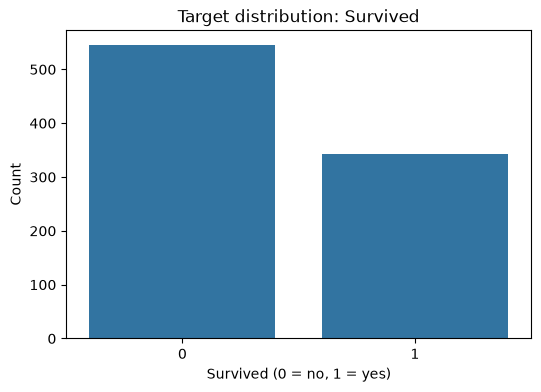

In [13]:
plt.figure(figsize=(6, 4))
sns.countplot(x=TARGET_COL, data=df)
plt.title("Target distribution: Survived")
plt.xlabel("Survived (0 = no, 1 = yes)")
plt.ylabel("Count")
plt.show()

Now let's drop the uncessary column `name`

In [14]:
df = df.drop(columns=["Name"])
print(df.columns.tolist())

['Survived', 'Pclass', 'Sex', 'Age', 'Siblings/Spouses Aboard', 'Parents/Children Aboard', 'Fare']


In [15]:
# dropna
print(df.isna().sum)
print("Prima:", df.shape)

df = df.dropna()
print("Dopo:", df.shape)

<bound method DataFrame.sum of      Survived  Pclass  ...  Parents/Children Aboard   Fare
0       False   False  ...                    False  False
1       False   False  ...                    False  False
2       False   False  ...                    False  False
3       False   False  ...                    False  False
4       False   False  ...                    False  False
..        ...     ...  ...                      ...    ...
882     False   False  ...                    False  False
883     False   False  ...                    False  False
884     False   False  ...                    False  False
885     False   False  ...                    False  False
886     False   False  ...                    False  False

[887 rows x 7 columns]>
Prima: (887, 7)
Dopo: (887, 7)


We see that in this type of dataset there isn't **missing values**

Now we are going to create the one-hot encoding, in order to clarify the categorical columns for having a column value like **True** or **False**

In [16]:
df = pd.get_dummies(df, columns=["Pclass", "Sex"]) 

Checking the correct changing of **one-hot encoding**

In [17]:
print(df.columns.tolist())
df.head()

['Survived', 'Age', 'Siblings/Spouses Aboard', 'Parents/Children Aboard', 'Fare', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Sex_female', 'Sex_male']


,Survived,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare,Pclass_1,Pclass_2,Pclass_3,Sex_female,Sex_male
0,0,22.0,1,0,7.2500,False,False,True,False,True
1,1,38.0,1,0,71.2833,True,False,False,True,False
2,1,26.0,0,0,7.9250,False,False,True,True,False
3,1,35.0,1,0,53.1000,True,False,False,True,False
4,0,35.0,0,0,8.0500,False,False,True,False,True


Splitting the data into Training data & Testing data, but before create the variable 

In [18]:
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

# checking 
print(X.shape, y.shape)
print(X.columns.tolist())

(887, 9) (887,)
['Age', 'Siblings/Spouses Aboard', 'Parents/Children Aboard', 'Fare', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Sex_female', 'Sex_male']


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (709, 9) (709,)
Test: (178, 9) (178,)


4. RandomForest Classifier 

    - Now let's get into the random forest classifier, with the `n_estimators = 10` and `random_state = RANDOM_STATE`

In [20]:
rf = RandomForestClassifier(n_estimators=10, random_state=RANDOM_STATE)

Now fit the data, for train the model on the training set 

In [21]:
rf.fit(X_train, y_train)   

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [22]:
y_pred = rf.predict(X_test)
print(y_pred)

[1 0 0 0 0 0 0 0 1 0 1 1 0 0 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0
 1 1 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1 1 0 0 1 0 1 0 0 0 1 0 0 0 1 1 0
 0 1 1 1 1 0 0 0 0 0 1 1 0 0 0 0 1 1 0 1 0 1 0 0 1 1 0 0 1 1 0 0 0 1 0 0 1
 0 0 0 0 1 0 1 0 0 1 0 0 0 1 0 0 1 1 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0
 0 0 0 1 0 0 0 1 0 1 1 0 0 1 0 1 0 1 0 1 0 1 1 1 1 0 0 1 1 0]


Now we have the prediction of the model, so we have to calculate the **Accuracy**

In [23]:
acc = accuracy_score(y_test, y_pred)
print("Accuracy score:", acc)

Accuracy score: 0.7865168539325843


## Titanic Survival Classification with Random Forest

1. **Objective**

The goal of this exercise is to solve a binary classification task on the Titanic passenger dataset: predicting whether a passenger survived (`Survived` = 1) or not (`Survived` = 0). The classifier used is a Random Forest with 10 trees, trained on 80% of the data and evaluated on the remaining 20%. No validation set and no cross-validation were used, as specified in the assignment.

2. **Data**

The dataset contains one row per passenger and the following features:

- **Pclass** (categorical): ticket class (1,2,3)

- **Name**: passenger name 

- **Sex** (categorical)

- **Age**

- **Siblings/Spouses Aboard**

- **Parents/Children Aboard**

- **Fare**

The target column is `Survived`. The exploratory analysis showed that the classes are moderately imbalanced: roughly 61% of passengers did not survive and 39% did. A trivial model that always predicts "did not survive" would therefore reach an accuracy of about 61%, which is used here as a baseline.

3. **Methodology**

    1. **Loading and inspection** of the CSV file (shape, column types, summary statistic, target distribution)

    2. **Dropping unnecessary columns**: only `Name` was removed, since it is an identifier and not a meaningful predictor 

    3. **Handling missing values**: rows with missing values were removed with `dropna()`. The check with `isna().sum()` showed that no rows needed to be discrarded.

    4. **One-hot encoding** of the categorical variables `Pclass` and `Sex` with `pd.get_dummies`, producing the column `Pclass_1`, `Pclass_2`, `Pclass_3`, `Sex_female` and `Sex_male`. `Pclass` was encoded explicitly because it is store as a number but has no meaningful numerical order.

    5. **Feature/target separation**: `X` contains all columns except `Survived`; `y` contains `Survived`. 

    6. **Train/test split**: 80% training and 20% test, using `train_test_split` with `test_size=0.2` and `random_state=42` for reproducibility.

    7. **Model**: `RandomForestClassifier(n_estimators=10, random_state=42)`, fitted on the training set only 

    8. **Evaluation**: predictions on the test set and accuracy computed with `accuracy_score`

4. **Random Forest in Brief**

A Random Forest is an ensemble of decision tree. Each tree is trained on a bootstrap sample of training data, and at each split only a random subset of the features is considered. This makes the trees different from one another. The final prediction is the majority vote of all trees, which reduces the overfitting typical of a single decision tree.

5. **Results**

The model reached an accuracy of **0.7865** on the test set, which corresponds to 140 correct predictions out of 178 test passengers. This is about 17 percentage points above the 61% baseline, showing that the model learns meaningful patterns from the features.

**Model**

| Model | Test accuracy |
|---|---|
| Baseline (always predict "did not survive") | ~0.61 |
| Random Forest (10 trees) | 0.7865 |

6. **Discussion and limitations**

- **Variability**: with only 10 trees and a single train/test split, the result is sensitive to the random seed. With a test set of 178 passengers, each passenger corresponds to about 0.56 percentage points, so a different split could easily change the accuracy by a few points.

- **No validation**: since neither a validation set nor cross-validation was used, the reported accuracy is a single estimate and its uncertainty is unknown

- **Accuracy only**: accuracy does not show which type of error the model makes (false positives vs. false negatives). A confusion matrix, precision and recall would give a more complete picture. 

- **Feature choiche**: only `Name` was dropped, although other features may be of limited use. Feature importances could be inspected to identify the most informative variables

7. **Conclusion**

A Random Forest with 10 trees, trained on the Titanic passenger data with one-hot encoded categorical variables, achieves an accuracy of about 78.7% on heald-out data, clearly outperforming the majority-class baseline. Possible improvements include using more trees, cross-validation for a more reliable estimate, and analysing feature importances and per-class metrics.

### Resolution Exercise 2

In [24]:
from sklearn.feature_selection import RFE 

First of all, let's create the selector, withe best 3 features

In [25]:
selector = RFE(
    estimator=RandomForestClassifier(n_estimators=10, random_state=RANDOM_STATE),
    n_features_to_select=3,
)

Then we have to train on the training data

In [26]:
selector.fit(X_train, y_train)

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",RandomForestC...ndom_state=42)
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",3
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only available when `estimator` is a classifier.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,RandomForestClassifier,RandomForestC...ndom_state=42)
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['Age','Siblings/Spouses Aboard','Parents/Children Aboard',...,'Pclass_3', 'Sex_female','Sex_male']"
n_features_ n_features_: intThe number of selected features.,int64,np.int64(3)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,9


Print the name of the 3 columns selected

In [29]:
print(X.columns[selector.get_support()].tolist())

['Age', 'Fare', 'Sex_female']


And now we remake the train on the new column

In [31]:
X_train_sel = selector.transform(X_train)
X_test_sel = selector.transform(X_test)

rf_sel = RandomForestClassifier(n_estimators=10, random_state=RANDOM_STATE)
rf_sel.fit(X_train_sel, y_train)

print("Accuracy:", accuracy_score(y_test, rf_sel.predict(X_test_sel)))

Accuracy: 0.7808988764044944


## Exercise 2: Feature selection with RFE

1. **Objective**

Repeat Exercise 1 applying feature selection, keeping only the top three features and printing their names with `get_support()`.

2. **Methodology**

    1. Same preprocessing as Exercise 1 (drop `Name`, `dropna()`, one-hot encoding of `Pclass` and `Sex`, 80/20 split with `random_state = 42`).

    2. **Selector**: RFE (Recursive Feature Elimination) with `RandomForestClassifier(n_estimators=10)` as estimator and `n_features_to_select=3`. At each step the least important feature is removed until only three remain.

    3. The selector was fitted **on the training set only**, to avoid data leakage from the test set.

    4. The selected features were obtained with `X.columns[selector.get_support()]`.

    5. A new Random Forest (10 trees) was trained on the reduced data (`selector.transform`) and evaluated on the test set.

3. **Results**

Selected features: **`Age`, `Fare`, `Sex_female`**

| Model | Features | Test accuracy |
| --- | --- | --- |
| Random Forest (Exercise 1) | all | 0.7865 |
| Random Forest + RFE | top 3 | 0.7808 |

4. **Discussion**

- The three selected features are `Age, Fare, Sex_female`, which is consistent with / different from what one would expect (e.g., `Sex` and `Fare` are usually strongly related to survival).

- With 3 features the accuracy is `lower` that with all features, so the discarded features carry `some` useful information 

- As in Exercise 1, the result depends on the single train/test split on the small number of trees.
